C3S CORDEX - Remapping with clisops + xESMF
===========================================

In an extensive test of remapping C3S CORDEX datasets with the developped and endorsed tools (`clisops` and `xESMF`), three major issues were discovered:

- CORDEX data that is mostly remapped to a grid of larger extent:
  -  for the nearest neighbour algorithm, each target grid cell is assigned a value from the nearest neighbour in the source grid, even in areas where the target grid is unmapped or unrepresented in the source grid. As a result, and implicit extrapolation occurs in areas outside the source grid’s domain
  -  [xESMF PR #444](https://github.com/pangeo-data/xESMF/pull/444) resolves this issue by altering the remapping weights after their generation to remove the contribution of source grid cells at the domain edge
- `c3s-cordex.output.ANT-44.DMI.ECMWF-ERAINT.evaluation.r1i1p1.DMI-HIRHAM5.v1.day.tas.v20201001` (`tas_ANT-44_ECMWF-ERAINT_evaluation_r1i1p1_DMI-HIRHAM5_v1_day_20060101-20101231.nc`)
  - failed because of a longitudinal extent of `-165.7095` to `193.08`
  - Problem was fixed with the longitude frame fix
- `c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915` (`tas_ARC-44_ECMWF-ERAINT_evaluation_r1i1p1_BCCR-WRF331_v1_day_20010101-20051231.nc`)
  - failed because cells have only 2 instead of 4 vertices: eg. `lat_bnds(rlat, rlon, bnds)` with `bnds=2`
  - Fixed by dropping `lat_bnds`, `lon_bnds` and potentially calculating the bounds if the original bounds have incorrect dimension sizes

## Basic Imports

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import xesmf as xe
import xarray as xr
import cf_xarray as cfxr
import clisops.core as clore
import clisops.ops as clops
import clisops as cl
import roocs_grids as rg
from glob import glob

## Allow multiple outputs per cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

## Turn off warnings?
import warnings
warnings.simplefilter("ignore")

# Flush weights cache
clore.weights_cache_flush(verbose=True)

print("Using xESMF in version %s" % xe.__version__)
print("Using xarray in version %s" % xr.__version__)
print("Using cf_xarray in version %s" % cfxr.__version__)
print("Using clisops in version %s" % cl.__version__)

Flushing the clisops weights cache ('/home/ms/.local/share/clisops/grid_weights'). Removing ...
 - /home/ms/.local/share/clisops/grid_weights/weights_ff47f7d25e73cd1376206a5e2cfd2258_2338a6e18b30a0457874c9c2ea261498_unperi_skip-degen_nearest_s2d.json
 - /home/ms/.local/share/clisops/grid_weights/weights_f0f9dd367381cb08e2a7523812926c9a_0d2a96b565cfb2953538af0a9dec4dd4_unperi_skip-degen_conservative.json
 - /home/ms/.local/share/clisops/grid_weights/weights_5c237c27859c93536a8548ae5c4a108d_cf3370f8299ac30ffd3cc7eae04932e9_unperi_skip-degen_conservative.json
 - /home/ms/.local/share/clisops/grid_weights/weights_b6a79f41db4bff0553254e19581c21b2_d1c517eb0f4362acdc7e2016655a68dd_peri_skip-degen_nearest_s2d.json
 - /home/ms/.local/share/clisops/grid_weights/weights_7bfb59698606d04f4195f57c6bfb2bc6_8226556e8b33c60acc7187fb4ae217a9_peri_skip-degen_conservative.json
 - /home/ms/.local/share/clisops/grid_weights/weights_1f958d9fc87471c31538057a57eb25fe_26d9565d114a49f26483c8c046db38e0_unperi_ski

## Demonstration of correct domain masking of nearest neighbour remapping

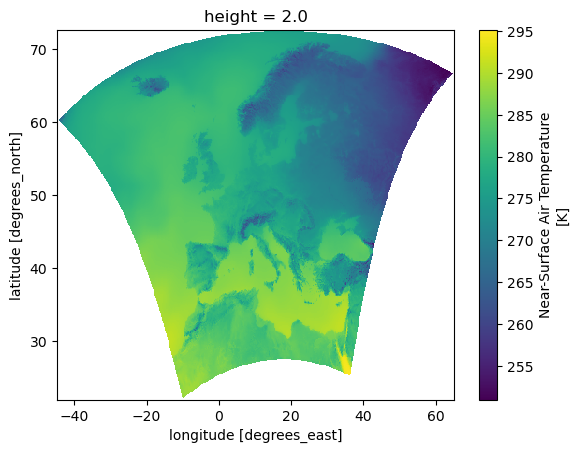

In [2]:
# Source data
ds_in = xr.open_dataset(
    "tas_EUR-11_MPI-M-MPI-ESM-LR_rcp85_r3i1p1_GERICS-REMO2015_v1_mon_200601-201012.nc"
).isel(time=0)

# Remapping & Plot
ds_out = clops.regrid(
    ds_in, grid="adaptive", method="nearest_s2d", output_type="xarray"
)[0]
ds_out.tas.plot()

## Demonstration of correct remapping of `c3s-cordex.output.ANT-44.DMI.ECMWF-ERAINT.evaluation.r1i1p1.DMI-HIRHAM5.v1.day.tas.v20201001`

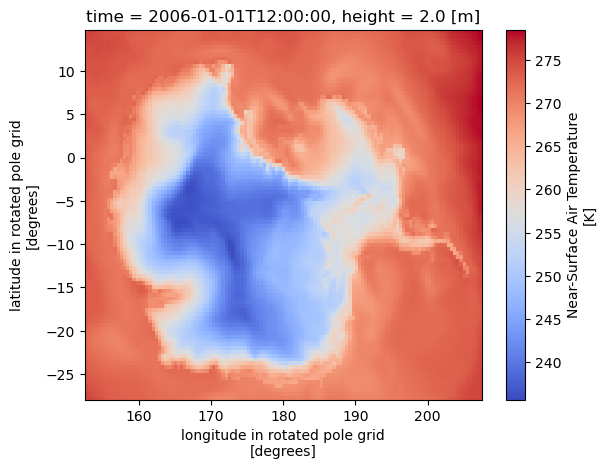

In [3]:
# Source data & Plot
ds_in = xr.open_dataset(
    "tas_ANT-44_ECMWF-ERAINT_evaluation_r1i1p1_DMI-HIRHAM5_v1_day_20060101-20101231.nc"
).isel(time=0)
ds_in.tas.plot(cmap="coolwarm")

In [4]:
grid = clore.Grid(ds_in)
grid

clisops 97x125_cells_grid
Lat x Lon:        97 x 125
Average resolution (x,y): (2.9030232583322833, 0.3533788522084554)
Gridcells:        12125
Format:           CF
Type:             curvilinear
Extent (x):       global
Extent (y):       regional
Source:           Dataset
Bounds?           False
Degenerate cells? None
Duplicated cells? False
Permanent Mask:   
md5 hash:         b6a79f41db4bff0553254e19581c21b2

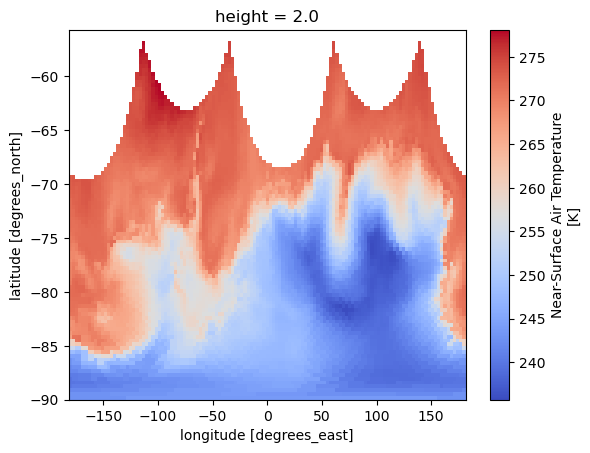

In [5]:
# Remapping & Plot
ds_out = clops.regrid(
    ds_in, grid="adaptive", method="nearest_s2d", output_type="xarray"
)[0]
ds_out.tas.plot(cmap="coolwarm")

Text(0.5, 1.0, 'TAS over Antarctica')

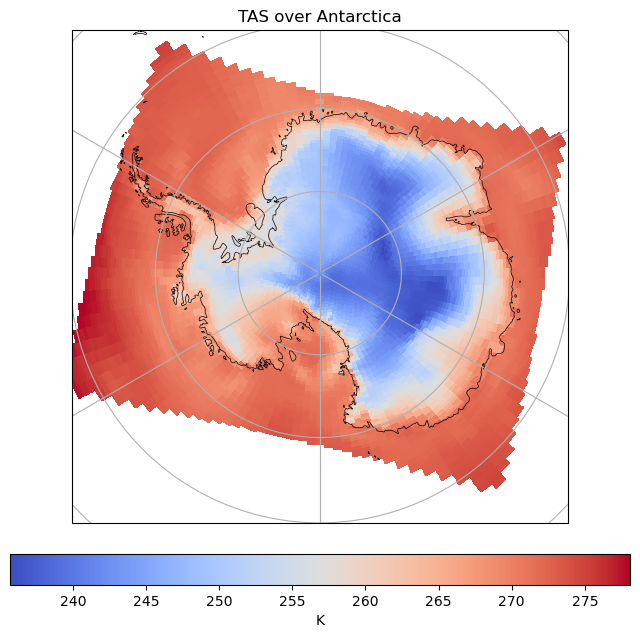

In [6]:
# Polar Stereographic Plot

fig = plt.figure(figsize=(8, 8))

# Use a South Polar Stereographic projection
proj = ccrs.SouthPolarStereo()

ax = plt.subplot(1, 1, 1, projection=proj)

# Set the map extent to show the Antarctic region
ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(draw_labels=False)

# Plot the data
# transform=ccrs.PlateCarree() tells cartopy the data's coordinate system
tas_plot = ax.pcolormesh(
    ds_out.lon,
    ds_out.lat,
    ds_out.tas,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
)

# Add colorbar
cbar = plt.colorbar(tas_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label(f"{ds_out.tas.units}")

plt.title(f"TAS over Antarctica")
plt.show()

## Demonstration of correct remapping of `c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915`

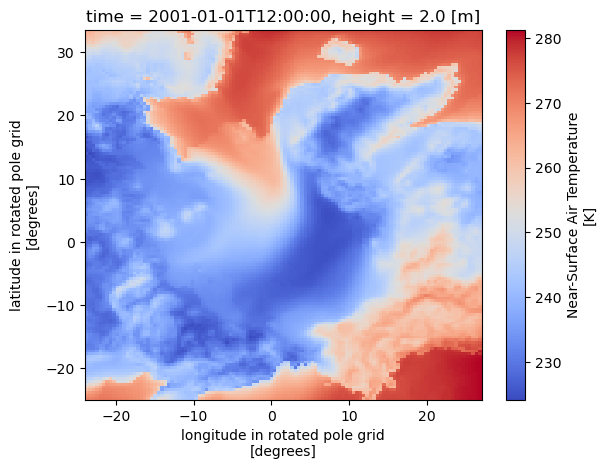

In [7]:
# Source data & Plot
ds_in = xr.open_dataset(
    "tas_ARC-44_ECMWF-ERAINT_evaluation_r1i1p1_BCCR-WRF331_v1_day_20010101-20051231.nc"
).isel(time=0)
ds_in.tas.plot(cmap="coolwarm")

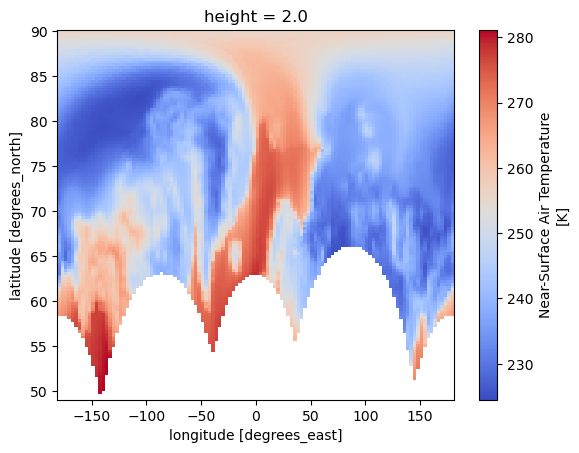

In [8]:
# Remapping & Plot
ds_out = clops.regrid(
    ds_in, grid="adaptive", method="conservative", output_type="xarray"
)[0]
ds_out.tas.plot(cmap="coolwarm")

Text(0.5, 1.0, 'TAS over Antarctica')

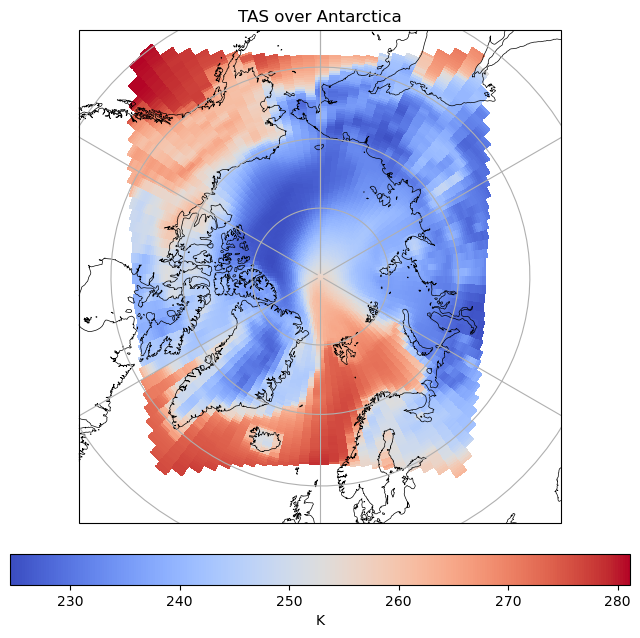

In [9]:
# Polar Stereographic Plot

fig = plt.figure(figsize=(8, 8))

# Use a North Polar Stereographic projection
proj = ccrs.NorthPolarStereo()

ax = plt.subplot(1, 1, 1, projection=proj)

# Set the map extent to show the Antarctic region
ax.set_extent([-180, 180, 90, 55], ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(draw_labels=False)

# Plot the data
# transform=ccrs.PlateCarree() tells cartopy the data's coordinate system
tas_plot = ax.pcolormesh(
    ds_out.lon,
    ds_out.lat,
    ds_out.tas,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
)

# Add colorbar
cbar = plt.colorbar(tas_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label(f"{ds_out.tas.units}")

plt.title(f"TAS over Antarctica")
plt.show()

## Comparison with ATLAS_v0

In [10]:
import math
import textwrap


def plot_ds(ds_atlas, ds, subtitle0=None, subtitle1=None, cbar=False):
    # Create panel plot
    fig, axes = plt.subplots(
        ncols=2,
        nrows=1,
        figsize=(20, 7),
        subplot_kw={"projection": ccrs.Mercator(central_longitude=150)},
    )

    ds_atlas.plot.pcolormesh(
        ax=axes[0],
        vmin=250,
        vmax=320,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    ds.plot.pcolormesh(
        ax=axes[1],
        vmin=250,
        vmax=320,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    if subtitle0:
        axes[0].title.set_text("\n".join(textwrap.wrap(subtitle0, 40)))
    if subtitle1:
        axes[1].title.set_text("\n".join(textwrap.wrap(subtitle1, 40)))

    for axis in axes.flatten():
        axis.coastlines()
        axis.set_xlabel("lon")
        axis.set_ylabel("lat")
    plt.show()

In [11]:
ds_atlas = {}
for domain in ["AFR", "AUS", "NAM", "SEA"]:
    ds_atlas[domain] = xr.open_dataset(
        f"testdata/ATLAS_v0_CORDEX/t_CORDEX-{domain}_historical_mon_197001-200512.nc"
    )

In [12]:
for domain in ["AFR", "AUS", "NAM", "SEA"]:
    for i in range(ds_atlas[domain].sizes["member"]):
        print()
        print(i)
        # id example: c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915
        id = f"c3s-cordex.output.{domain}-*.{ds_atlas[domain].rcm_institution.data[i]}.{ds_atlas[domain].gcm_institution.data[i]}-{ds_atlas[domain].gcm_model.data[i]}.historical.{ds_atlas[domain].gcm_variant.data[i]}.{ds_atlas[domain].rcm_institution.data[i]}-{ds_atlas[domain].rcm_model.data[i]}.{ds_atlas[domain].rcm_variant.data[i]}.tas.mon"
        print(id)
        print(id.replace(".", "/") + "/*/*_1970-*.nc")


0
c3s-cordex.output.AFR-*.CCCma.CCCma-CanESM2.historical.r1i1p1.CCCma-CanRCM4.r2.tas.mon
c3s-cordex/output/AFR-*/CCCma/CCCma-CanESM2/historical/r1i1p1/CCCma-CanRCM4/r2/tas/mon/*/*_1970-*.nc

1
c3s-cordex.output.AFR-*.SMHI.CCCma-CanESM2.historical.r1i1p1.SMHI-RCA4.v1.tas.mon
c3s-cordex/output/AFR-*/SMHI/CCCma-CanESM2/historical/r1i1p1/SMHI-RCA4/v1/tas/mon/*/*_1970-*.nc

2
c3s-cordex.output.AFR-*.UQAM.CCCma-CanESM2.historical.r1i1p1.UQAM-CRCM5.v1.tas.mon
c3s-cordex/output/AFR-*/UQAM/CCCma-CanESM2/historical/r1i1p1/UQAM-CRCM5/v1/tas/mon/*/*_1970-*.nc

3
c3s-cordex.output.AFR-*.CLMcom.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CLMcom-CCLM4-8-17.v1.tas.mon
c3s-cordex/output/AFR-*/CLMcom/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/CLMcom-CCLM4-8-17/v1/tas/mon/*/*_1970-*.nc

4
c3s-cordex.output.AFR-*.SMHI.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.SMHI-RCA4.v1.tas.mon
c3s-cordex/output/AFR-*/SMHI/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/SMHI-RCA4/v1/tas/mon/*/*_1970-*.nc

5
c3s-cordex.output.AFR-*.SMHI

4 clisops tas_AFR-44_CNRM-CERFACS-CNRM-CM5_historical_r1i1p1_SMHI-RCA4


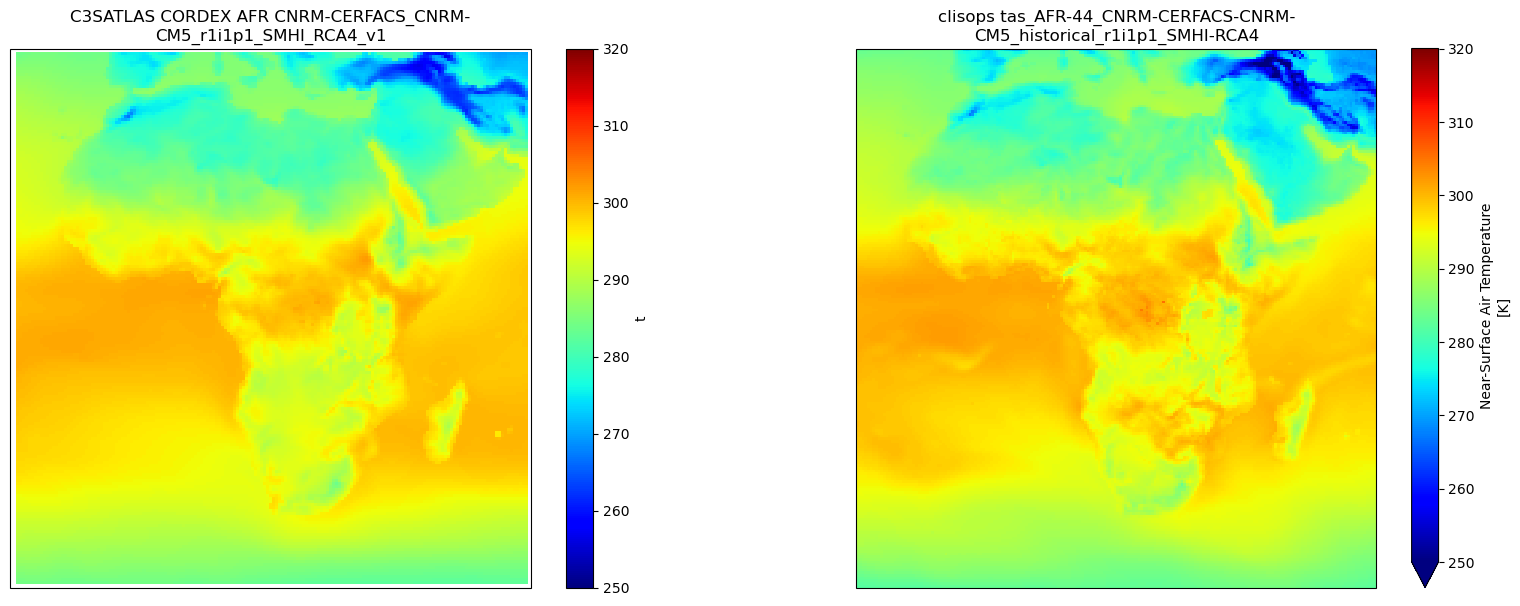

0 clisops tas_AUS-44i_CCCma-CanESM2_historical_r1i1p1_CSIRO-CCAM-2008


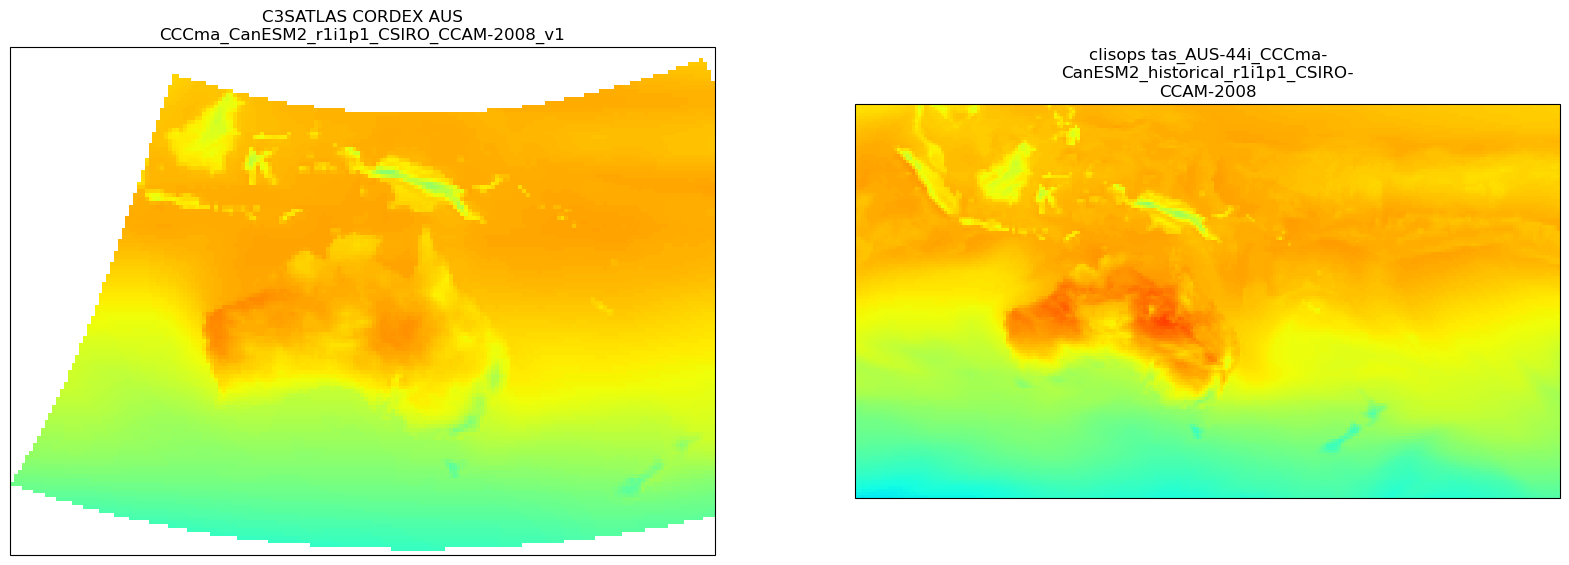

19 clisops tas_NAM-22_NOAA-GFDL-GFDL-ESM2M_historical_r1i1p1_OURANOS-CRCM5


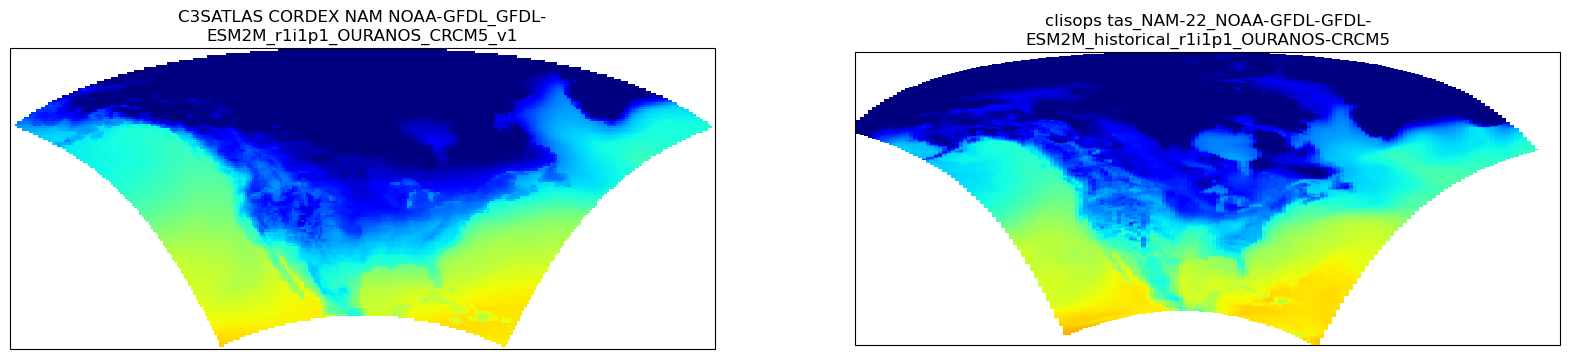

10 clisops tas_SEA-22_NCC-NorESM1-M_historical_r1i1p1_ICTP-RegCM4-7


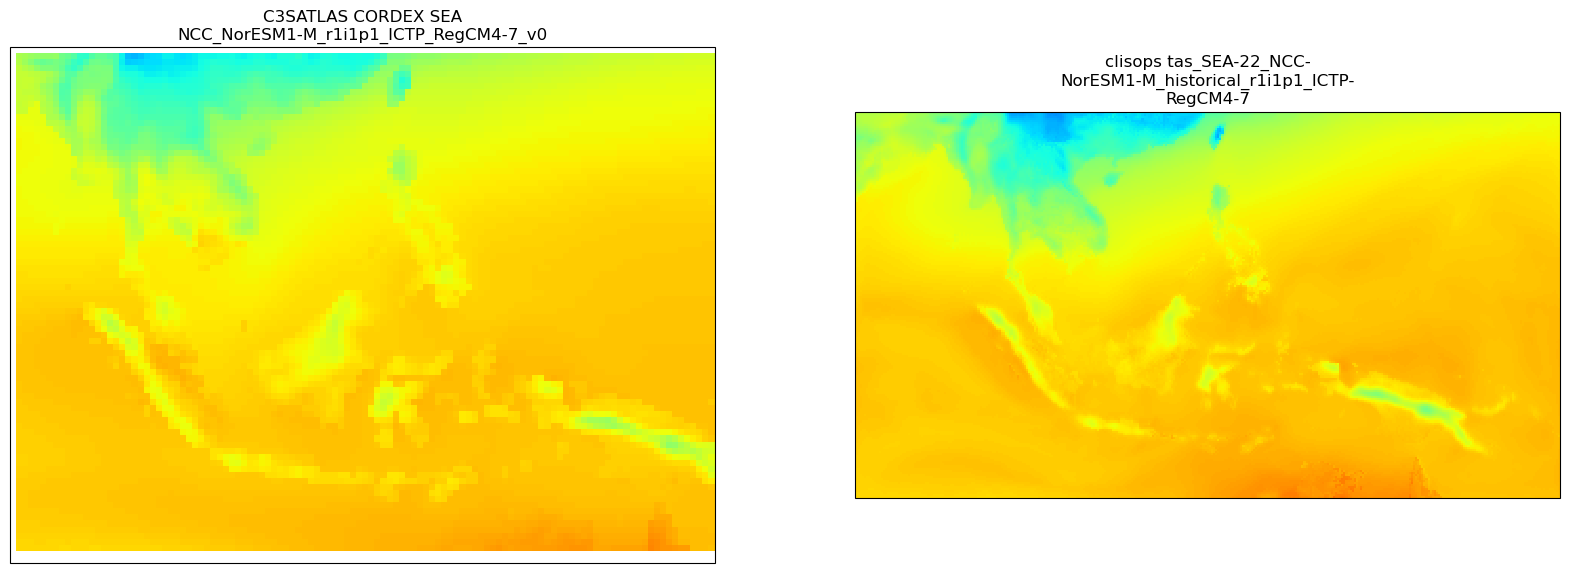

In [13]:
sel_member = {"AFR": 4, "AUS": 0, "NAM": 19, "SEA": 10}
for domain in ["AFR", "AUS", "NAM", "SEA"]:
    # if domain != "AFR": continue
    i = sel_member[domain]
    filepath = glob(f"testdata/ATLAS_v0_CORDEX/{i}_*.nc")[0]
    title1 = "clisops " + "_".join(filepath.split("/")[-1].split("_")[1:7])
    title0 = (
        "C3SATLAS CORDEX "
        + domain
        + " "
        + ds_atlas[domain]["member_id"].values[i]
    )
    ds = xr.open_dataset(filepath)

    method = "conservative"
    print(i, title1)

    ds_regrid = clops.regrid(
        ds,
        method=method,
        adaptive_masking_threshold=1,
        grid="adaptive",
        output_type="xarray",
    )[0]
    plot_ds(
        ds_atlas[domain].t.isel(member=i, time=0) + 273.15,
        ds_regrid.tas.isel(time=0),
        title0,
        title1,
        cbar=domain == "AFR",
    )

## Comparison with ATLAS_v1

In [14]:
import math
import textwrap


def plot_ds(ds_atlas, ds, subtitle0=None, subtitle1=None, cbar=False):
    # Create panel plot
    fig, axes = plt.subplots(
        ncols=2,
        nrows=1,
        figsize=(20, 7),
        subplot_kw={"projection": ccrs.Mercator(central_longitude=150)},
    )

    ds_atlas.plot.pcolormesh(
        ax=axes[0],
        vmin=240,
        vmax=300,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    ds.plot.pcolormesh(
        ax=axes[1],
        vmin=240,
        vmax=300,
        shading="auto",
        add_colorbar=cbar,
        cmap="jet",
    )
    if subtitle0:
        axes[0].title.set_text("\n".join(textwrap.wrap(subtitle0, 40)))
    if subtitle1:
        axes[1].title.set_text("\n".join(textwrap.wrap(subtitle1, 40)))

    for axis in axes.flatten():
        axis.coastlines()
        axis.set_xlabel("lon")
        axis.set_ylabel("lat")
    plt.show()

In [15]:
ds_atlas = {}
for domain in ["EUR-11"]:
    ds_atlas[domain] = xr.open_dataset(
        f"testdata/ATLAS_v1_CORDEX/t_CORDEX-{domain}_historical_mon_197001-200512.nc"
    )

In [16]:
for domain in ["EUR-11"]:
    for i in range(ds_atlas[domain].sizes["member"]):
        print()
        print(i)
        # id example: c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915
        id = f"c3s-cordex.output.{domain}-*.{ds_atlas[domain].rcm_institution.data[i]}.{ds_atlas[domain].gcm_institution.data[i]}-{ds_atlas[domain].gcm_model.data[i]}.historical.{ds_atlas[domain].gcm_variant.data[i]}.{ds_atlas[domain].rcm_institution.data[i]}-{ds_atlas[domain].rcm_model.data[i]}.{ds_atlas[domain].rcm_variant.data[i]}.tas.mon"
        print(id)
        print(id.replace(".", "/") + "/*/*_1970-*.nc")


0
c3s-cordex.output.EUR-11-*.CLMcom.CCCma-CanESM2.historical.r1i1p1.CLMcom-CCLM4-8-17.v1.tas.mon
c3s-cordex/output/EUR-11-*/CLMcom/CCCma-CanESM2/historical/r1i1p1/CLMcom-CCLM4-8-17/v1/tas/mon/*/*_1970-*.nc

1
c3s-cordex.output.EUR-11-*.GERICS.CCCma-CanESM2.historical.r1i1p1.GERICS-REMO2015.v1.tas.mon
c3s-cordex/output/EUR-11-*/GERICS/CCCma-CanESM2/historical/r1i1p1/GERICS-REMO2015/v1/tas/mon/*/*_1970-*.nc

2
c3s-cordex.output.EUR-11-*.CLMcom-ETH.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CLMcom-ETH-COSMO-crCLIM-v1-1.v1.tas.mon
c3s-cordex/output/EUR-11-*/CLMcom-ETH/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/CLMcom-ETH-COSMO-crCLIM-v1-1/v1/tas/mon/*/*_1970-*.nc

3
c3s-cordex.output.EUR-11-*.CLMcom.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CLMcom-CCLM4-8-17.v1.tas.mon
c3s-cordex/output/EUR-11-*/CLMcom/CNRM-CERFACS-CNRM-CM5/historical/r1i1p1/CLMcom-CCLM4-8-17/v1/tas/mon/*/*_1970-*.nc

4
c3s-cordex.output.EUR-11-*.CNRM.CNRM-CERFACS-CNRM-CM5.historical.r1i1p1.CNRM-ALADIN63.v2.tas.mon
c3s-cordex/out

60 clisops tas_EUR-11_MPI-M-MPI-ESM-LR_historical_r3i1p1_GERICS-REMO2015


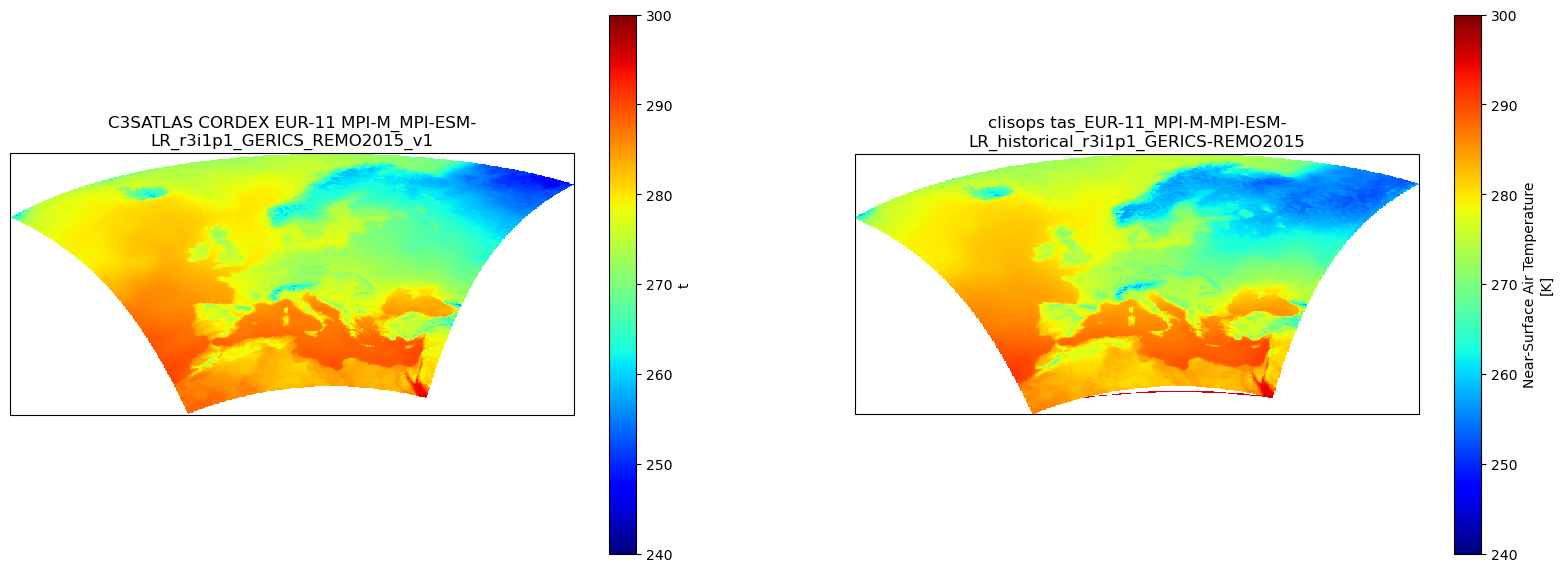

In [17]:
sel_member = {"EUR-11": 60}
for domain in ["EUR-11"]:
    i = sel_member[domain]
    filepath = glob(f"testdata/ATLAS_v1_CORDEX/{i}_*.nc")[0]
    title1 = "clisops " + "_".join(filepath.split("/")[-1].split("_")[1:7])
    title0 = (
        "C3SATLAS CORDEX "
        + domain
        + " "
        + ds_atlas[domain]["member_id"].values[i]
    )
    ds = xr.open_dataset(filepath)

    method = "conservative"
    print(i, title1)

    ds_regrid = clops.regrid(
        ds,
        method=method,
        adaptive_masking_threshold=1,
        grid="adaptive",
        output_type="xarray",
    )[0]
    plot_ds(
        ds_atlas[domain].t.isel(member=i, time=0) + 273.15,
        ds_regrid.tas.isel(time=0),
        title0,
        title1,
        cbar=domain == "EUR-11",
    )